# Fase 3 — Conectividad efectiva (EC)

**Método.** Partimos de $G\cdot\mathrm{SC}$ y ajustamos pesos **dirigidos y no negativos** $C_{jk}$ (de la región $k$ hacia la $j$) con la regla iterativa de Deco et al. (2019) y Gilson et al. (2016):
$$C_{jk} \leftarrow \max\!\big(0,\; C_{jk} + \varepsilon\,[(\mathrm{FC}^{\rm emp}_0-\mathrm{FC}^{\rm mod}_0) + (\mathrm{FC}^{\rm emp}_\tau-\mathrm{FC}^{\rm mod}_\tau)]_{jk}\big).$$
- $\mathrm{FC}_\tau$ es la covarianza normalizada con retardo $\tau=1.44$ s. Este término rompe la simetría y es lo que permite inferir la dirección de las conexiones.
- Las estadísticas del modelo son analíticas (`FilteredSpectrum.covs`): 3000 iteraciones tardan unos 40 s.
- Se fija $a=-0.07$, el valor homogéneo de la Fase 2.

**Validación.** Ajustamos con 4 sujetos y evaluamos en 3. La referencia es el **techo de ruido**: cuánto predice la FC del grupo A a la del grupo B. Comparamos dos máscaras: todos los pares frente al 20 % de enlaces de SC más fuertes. Código: `src/fit_ec.py` y `src/spectra_check.py`.

techo de ruido A->B: r = 0.795
SC (test):           r = 0.435
EC todos  train r=0.945  test r=0.764 (máx 0.764)  test MSE=0.0595
EC top    train r=0.825  test r=0.665 (máx 0.672)  test MSE=0.0420
asimetría de EC = 0.43;  fracción de pesos en cero = 0.88


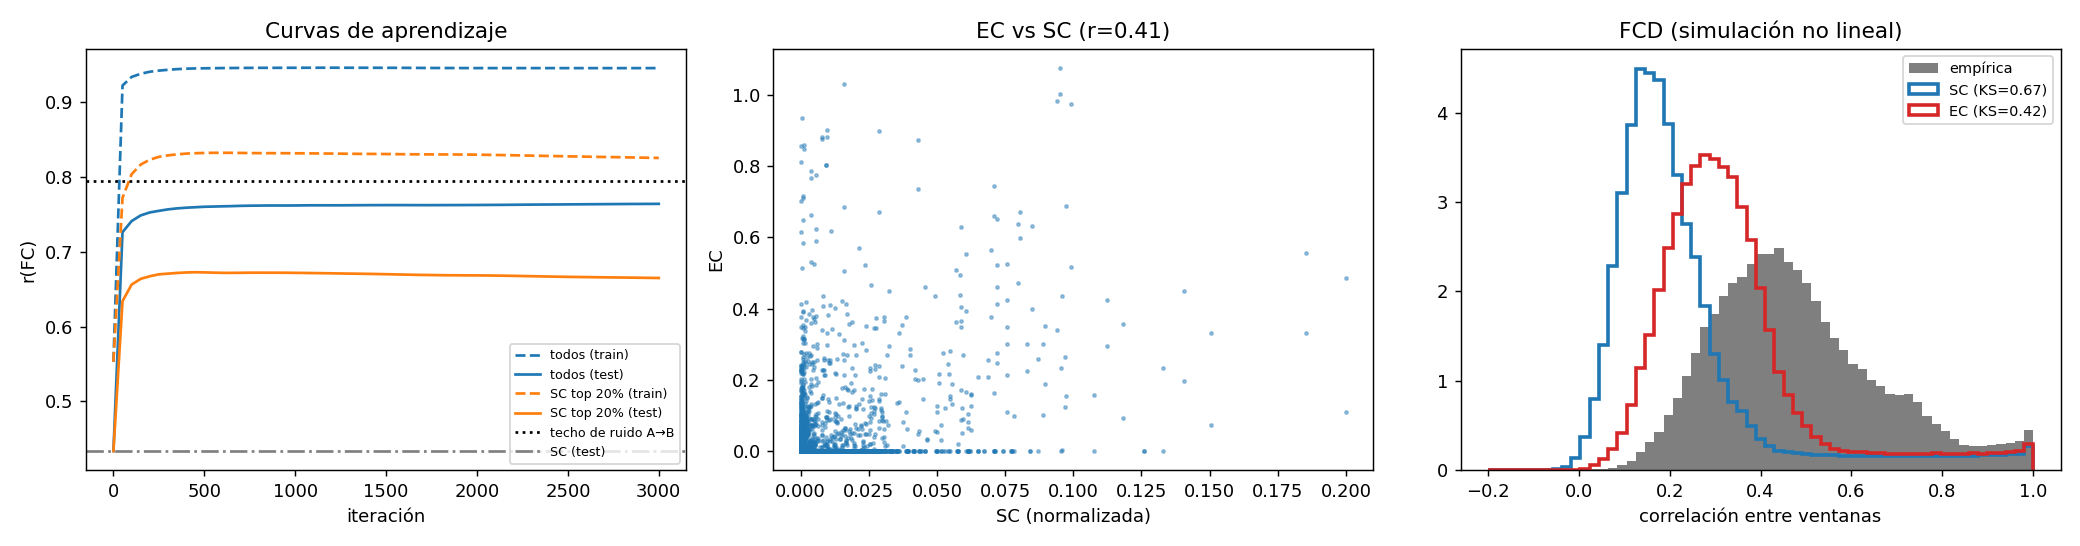

In [1]:
import numpy as np
from pathlib import Path
from IPython.display import Image, display
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
r = np.load(ROOT/'results'/'fase3_ec.npz')
print(f"techo de ruido A->B: r = {r['ceil'][0]:.3f}")
print(f"SC (test):           r = {r['sc_test'][0]:.3f}")
for k in ['curve_todos', 'curve_top']:
    c = r[k]; print(f"EC {k[6:]:6s} train r={c[-1,1]:.3f}  test r={c[-1,3]:.3f} (máx {c[:,3].max():.3f})  test MSE={c[-1,4]:.4f}")
print(f"asimetría de EC = {float(r['asym']):.2f};  fracción de pesos en cero = {np.mean(r['EC'][r['mask']]==0):.2f}")
display(Image(str(ROOT/'figures'/'fase3_ec_validacion.png')))

**Resultados.**
- **La EC casi alcanza el techo de ruido.** En los sujetos de prueba, $r=0.76$ frente a un máximo alcanzable de $0.80$ y a $0.43$ con la SC. Con todos los pares libres el ajuste sobreajusta (en entrenamiento $r=0.95$, por encima del techo), pero aun así generaliza mejor que la máscara anatómica (0.67). Ojo: el MSE en prueba (0.060) es peor que el de la SC (0.053), así que el *patrón* se predice bien pero el *nivel* no del todo.
- **La EC es dispersa y asimétrica.** Un 88 % de los pesos termina en cero, la asimetría es de 0.43 y su correlación con la SC es de solo 0.41. Con 7 sujetos, la *dirección* de cada enlace no es confiable todavía; tómala como ilustrativa.
- **Simulación no lineal:** $r(\mathrm{FC})$ sube de 0.54 a 0.93, pero el KS de la FCD solo baja de 0.67 a 0.42. La predicción "FC correcta implica FCD correcta" **se cumple solo a medias**.

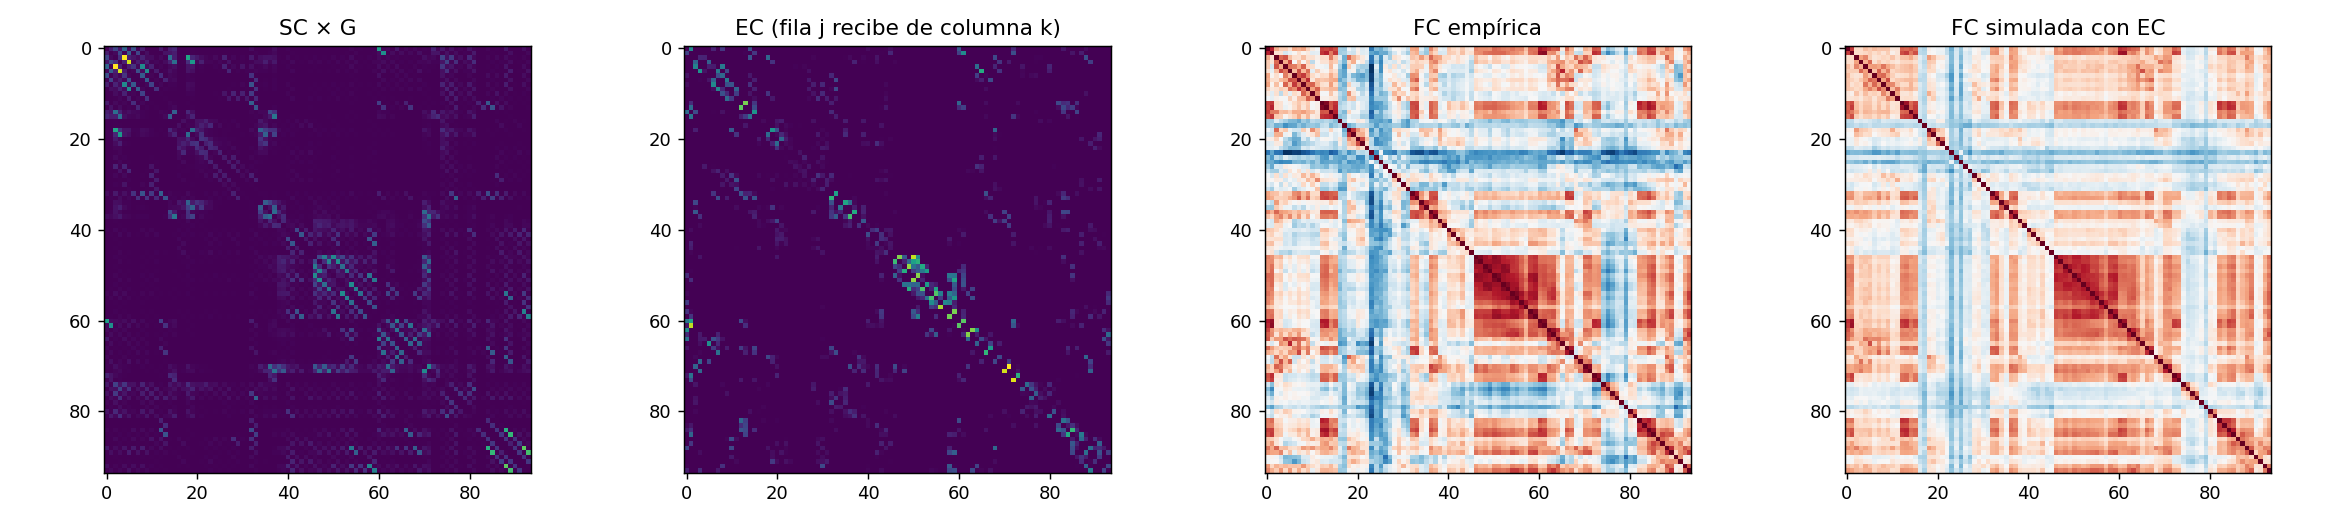

In [2]:
display(Image(str(ROOT/'figures'/'fase3_matrices.png')))

## ¿Qué le falta a la FCD? — controles

| Señales | Espectros | FC | Coherencia por frecuencia | KS(FCD) |
|---|---|---|---|---|
| modelo con SC | modelo | modelo (r=0.54) | modelo | 0.67 |
| modelo con EC | modelo | modelo (r=0.93) | modelo | 0.42 |
| híbrido | modelo | **empírica exacta** | — | 0.26 |
| control empírico | **empíricos por región** | **empírica exacta** | destruida | **0.09** |
| surrogado de fase | empíricos | empírica | empírica | **0.07** |

- El espectro *promedio* del modelo coincide con el empírico (centroide 0.034 frente a 0.033 Hz y unas 6.8 muestras efectivas por ventana en ambos), pero los espectros **de cada región** no.
- Con espectros por región y FC empíricos se recupera la FCD (KS = 0.09) aunque se destruya la coherencia entre frecuencias.

**Conclusión.** La FCD está determinada por (FC, espectros de cada región). La EC resuelve la FC; lo que falta son **los espectros regionales**, es decir, $\omega_j$ y $a_j$ ajustados a la forma espectral de cada región, no solo a su pico. En la Fase 2, $a_j$ no logró ajustar las autocorrelaciones porque $\omega_j$ estaba fija en un pico ruidoso. El siguiente paso es ajustar $(\omega_j, a_j)$ al espectro de cada región junto con la EC.

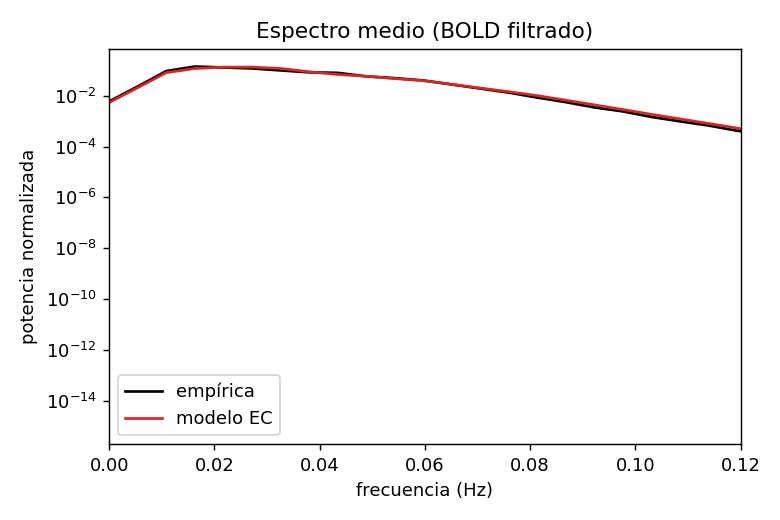

In [3]:
display(Image(str(ROOT/'figures'/'fase3_espectros.png')))